# 02 — Exploratory Data Analysis (EDA)

## Project Overview

This notebook focuses on exploring and understanding the integrated climate datasets for dry spell prediction in Gadarif State, Sudan.

The analysis aims to:

- Understand the target variable distribution.
- Examine descriptive statistics of climate features.
- Investigate feature distributions and relationships.
- Explore temporal patterns and trends.
- Identify potential outliers and data quality issues.

The merged datasets prepared in the previous notebook will be used as the starting point for this analysis.

## 2.1.1 Environment Setup and Data Loading

In this section, we will initialize the project environment, import the required libraries, and load the previously integrated training and testing datasets.

The original merged datasets will be loaded without applying additional preprocessing or transformations.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    TRAIN_DIR,
    TEST_DIR,
    DATA_DIR,
    MODELS_DIR,
    REPORTS_DIR
)

print("Project root:", PROJECT_ROOT)

Project root: D:\Users\PC\Desktop\To the new pc\Elzero\ML-Projects\IndabaX2025-DrySpell-Challenge


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
from src.data_loader import (
    load_and_standardize_datasets,
    merge_datasets
)

### 2.1.2 Load and Merge Datasets

In this subsection, the original training and testing datasets are loaded and standardized using the reusable functions implemented in `src/data_loader.py`.

The individual datasets are then merged into two unified DataFrames, `train_merged` and `test_merged`, using the date column as the common key.

No additional preprocessing, imputation, or feature transformations will be applied at this stage.

In [5]:
# Load and standardize training datasets
train_datasets = load_and_standardize_datasets(TRAIN_DIR)

# Load and standardize testing datasets
test_datasets = load_and_standardize_datasets(TEST_DIR)

# Merge datasets
train_merged = merge_datasets(train_datasets)
test_merged = merge_datasets(test_datasets)

print("Training dataset shape:", train_merged.shape)
print("Testing dataset shape:", test_merged.shape)

Training dataset shape: (2214, 18)
Testing dataset shape: (738, 17)


#### Key Findings

- The training dataset contains **2,214 rows and 18 columns**.
- The testing dataset contains **738 rows and 17 columns**.
- Both datasets were successfully loaded and merged using the reusable functions in `src/data_loader.py`.
- The resulting shapes match the integration results obtained in Notebook 01.
- No additional preprocessing or feature transformations have been applied.

The datasets are ready for exploratory data analysis (EDA).

## 2.2 Target Variable Analysis

The target variable, `dryspell_warn_7d`, represents the prediction label for the dry spell warning task.

This section investigates the distribution of the target classes to understand their frequency, relative proportions, and potential class imbalance.

Understanding the target distribution is essential for selecting appropriate evaluation metrics and modeling strategies.

### 2.2.1 Target Distribution

This subsection examines the frequency and percentage of each class in the training dataset.

The analysis includes a numerical summary and a visualization of the target class distribution.

,Count,Percentage (%)
dryspell_warn_7d,,
0,1890,85.365854
1,324,14.634146


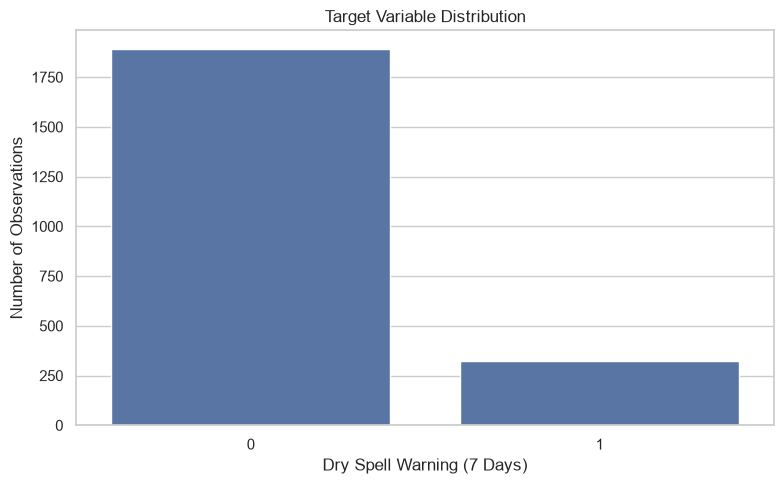

In [6]:
# Calculate target class counts
target_counts = train_merged["dryspell_warn_7d"].value_counts().sort_index()

# Calculate target class percentages
target_percentages = (
    train_merged["dryspell_warn_7d"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Combine results into a summary DataFrame
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_merged,
    x="dryspell_warn_7d"
)

plt.title("Target Variable Distribution")
plt.xlabel("Dry Spell Warning (7 Days)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

#### Key Findings

- The target variable contains two classes: 0 and 1.
- Class 0 represents 1,890 observations (85.37%).
- Class 1 represents 324 observations (14.63%).
- The target distribution exhibits a noticeable class imbalance, with approximately 5.83 observations of Class 0 for every observation of Class 1.
- A majority-class baseline classifier would achieve approximately 85.37% accuracy while failing to identify any Class 1 observations.

This imbalance must be considered during model development and evaluation, particularly when selecting classification metrics.

### 2.2.2 Class Imbalance Analysis

This subsection quantifies the degree of class imbalance and examines the performance of a simple majority-class baseline.

The baseline classifier always predicts the majority class (Class 0). Its performance illustrates why accuracy alone may be misleading for this classification task.

In [7]:
# Calculate class imbalance ratio
majority_count = target_counts.max()
minority_count = target_counts.min()

imbalance_ratio = majority_count / minority_count

# Majority-class baseline
baseline_accuracy = majority_count / len(train_merged) * 100

print(f"Majority class count: {majority_count}")
print(f"Minority class count: {minority_count}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.2f}%")

print("\nBaseline classification behavior:")
print("Class 0 Recall: 100%")
print("Class 1 Recall: 0%")

Majority class count: 1890
Minority class count: 324
Imbalance ratio: 5.83:1
Majority-class baseline accuracy: 85.37%

Baseline classification behavior:
Class 0 Recall: 100%
Class 1 Recall: 0%


### 2.3.1 Numerical Features Distribution

This subsection visualizes the distributions of all numerical input features using histograms and Kernel Density Estimation (KDE).

The visualizations help identify:
- Distribution shapes and skewness.
- Concentration and spread of values.
- Potential unusual distribution patterns.
- Differences in feature behavior.

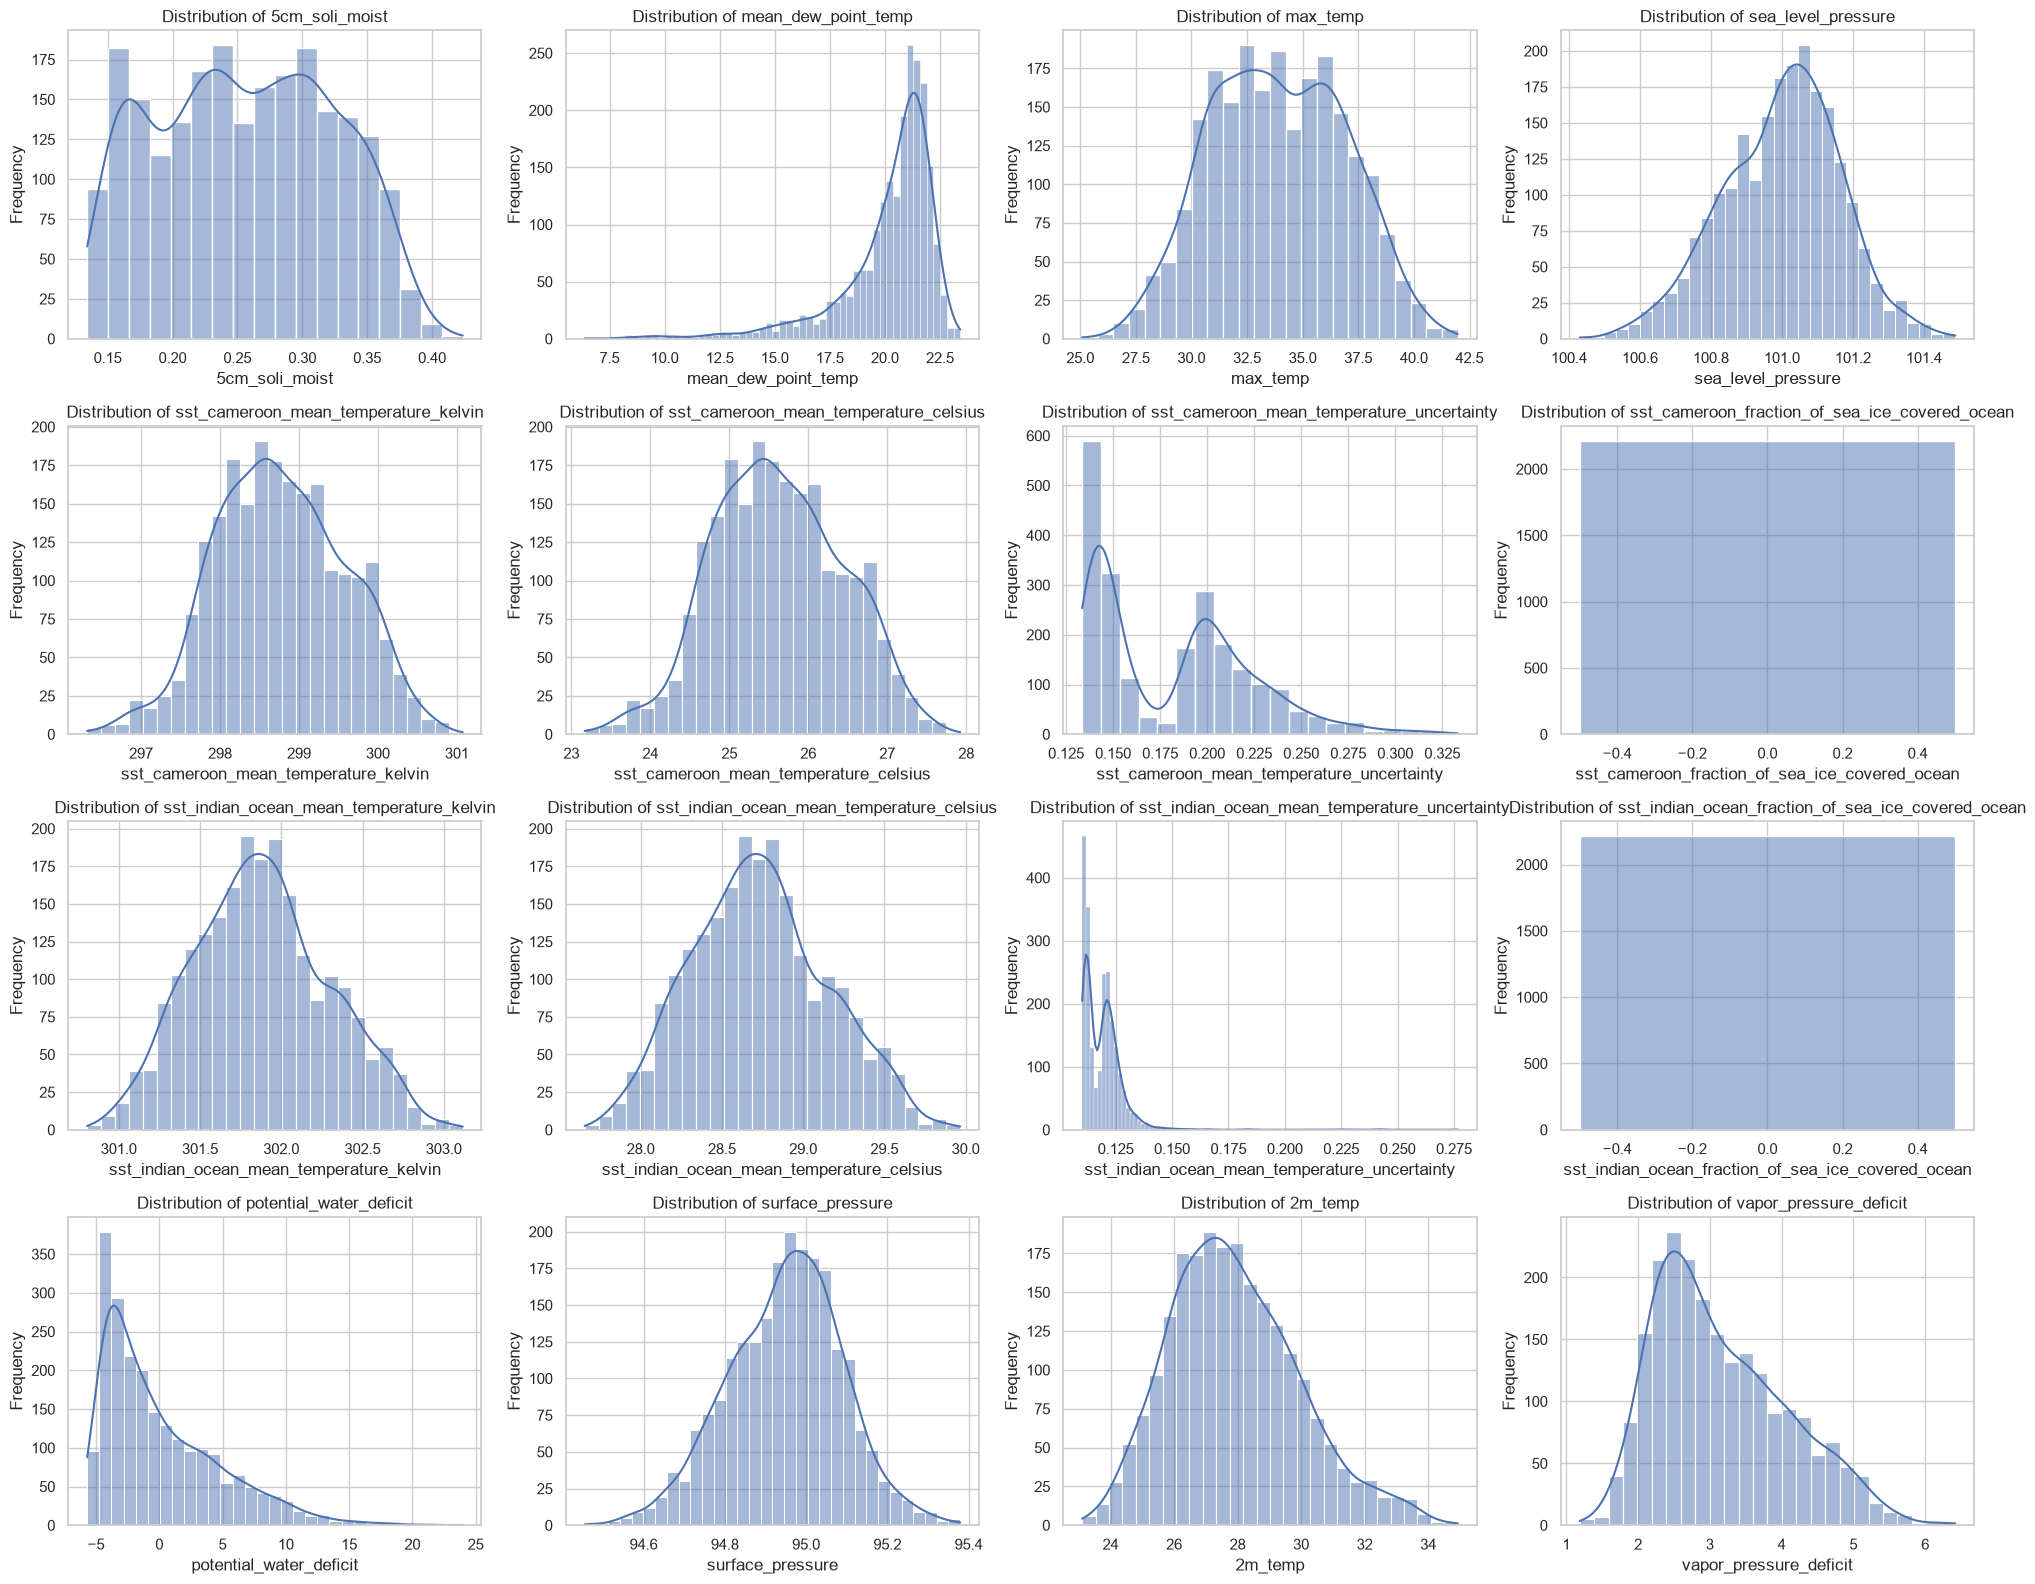

In [8]:
# Select numerical features, excluding the target variable
numerical_features = (
    train_merged
    .select_dtypes(include=np.number)
    .drop(columns=["dryspell_warn_7d"])
    .columns
)

# Create distribution plots
n_features = len(numerical_features)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 4 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=train_merged,
        x=feature,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Key Findings

- The numerical features exhibit different distribution shapes, including approximately symmetric, negatively skewed, positively skewed, and multimodal distributions.
- `mean_dew_point_temp` shows a noticeable negative skew.
- `potential_water_deficit` and `vapor_pressure_deficit` exhibit positive skewness.
- SST uncertainty features show non-symmetric distributions with multiple concentration regions.
- SST temperature measurements in Kelvin and Celsius represent the same underlying physical variable using different units, suggesting potential feature redundancy.
- The two sea-ice fraction features appear concentrated at zero and require numerical verification to determine whether they are constant.

Further statistical analysis is required before making feature selection or transformation decisions.

### 2.3.2 Statistical Summary and Distribution Diagnostics

This subsection examines descriptive statistics and distribution characteristics of numerical features.

The analysis includes:
- Mean and standard deviation.
- Minimum and maximum values.
- Median and quartiles.
- Number of unique values.
- Skewness.
- Standard deviation to identify potentially constant features.

In [9]:
# Generate descriptive statistics
feature_summary = train_merged[numerical_features].describe().T

# Add additional distribution diagnostics
feature_summary["n_unique"] = train_merged[numerical_features].nunique()
feature_summary["skewness"] = train_merged[numerical_features].skew()
feature_summary["variance"] = train_merged[numerical_features].var()

# Display the summary
display(
    feature_summary[
        [
            "count",
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max",
            "n_unique",
            "skewness",
            "variance"
        ]
    ].round(4)
)

,count,mean,std,min,25%,50%,75%,max,n_unique,skewness,variance
5cm_soli_moist,2214.0,0.2560,0.0677,0.1342,0.2010,0.2547,0.3104,0.4236,1429,0.0294,0.0046
mean_dew_point_temp,2214.0,20.1568,2.2092,6.3711,19.5543,20.8512,21.5486,23.4193,2156,-2.1647,4.8807
max_temp,2214.0,33.8974,3.0008,25.0857,31.5646,33.8002,36.2005,41.9700,2198,0.0320,9.0046
sea_level_pressure,2214.0,100.9987,0.1657,100.4301,100.8858,101.0133,101.1131,101.4882,1840,-0.2269,0.0275
sst_cameroon_mean_temperature_kelvin,2214.0,298.7681,0.8134,296.3181,298.1744,298.7217,299.3421,301.0740,2201,0.0236,0.6616
sst_cameroon_mean_temperature_celsius,2214.0,25.6181,0.8134,23.1681,25.0244,25.5717,26.1921,27.9240,2214,0.0236,0.6616
sst_cameroon_mean_temperature_uncertainty,2214.0,0.1820,0.0409,0.1335,0.1430,0.1889,0.2091,0.3332,1874,0.6775,0.0017
sst_cameroon_fraction_of_sea_ice_covered_ocean,2214.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,NaN,0.0000
sst_indian_ocean_mean_temperature_kelvin,2214.0,301.8810,0.4157,300.8053,301.5826,301.8618,302.1480,303.1164,2199,0.1910,0.1728
sst_indian_ocean_mean_temperature_celsius,2214.0,28.7310,0.4157,27.6553,28.4326,28.7118,28.9980,29.9664,2214,0.1910,0.1728


#### Key Findings

- Two SST sea-ice fraction features are constant across the training dataset, each containing only one unique value and zero variance.
- `mean_dew_point_temp` exhibits strong negative skewness (-2.1647).
- `sst_indian_ocean_mean_temperature_uncertainty` exhibits extreme positive skewness (5.9234).
- `potential_water_deficit` (1.2276) and `vapor_pressure_deficit` (0.6419) exhibit positive skewness.
- `2m_temp` shows mild positive skewness (0.4910).
- SST temperature measurements in Kelvin and Celsius have matching rounded distribution statistics, but their numbers of unique values differ. Their relationship requires further verification.
- No features are removed or transformed at this stage.

These findings will guide subsequent feature redundancy analysis and preprocessing decisions.

### 2.3.3 Outlier Exploration

This subsection investigates potential outliers in numerical input features using the Interquartile Range (IQR) method.

The analysis identifies observations below the lower bound or above the upper bound for each feature.

The detected observations are considered potential statistical outliers and will not be removed automatically, as extreme climate observations may represent meaningful environmental events.

In [10]:
# Calculate IQR-based outlier statistics
outlier_summary = []

for feature in numerical_features:
    Q1 = train_merged[feature].quantile(0.25)
    Q3 = train_merged[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train_merged[
        (train_merged[feature] < lower_bound) |
        (train_merged[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage (%)": len(outliers) / len(train_merged) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(4))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,5cm_soli_moist,0.0369,0.4745,0,0.0000
1,mean_dew_point_temp,16.5630,24.5399,163,7.3622
2,max_temp,24.6109,43.1542,0,0.0000
3,sea_level_pressure,100.5447,101.4541,12,0.5420
4,sst_cameroon_mean_temperature_kelvin,296.4229,301.0937,4,0.1807
5,sst_cameroon_mean_temperature_celsius,23.2729,27.9436,4,0.1807
6,sst_cameroon_mean_temperature_uncertainty,0.0438,0.3084,13,0.5872
7,sst_cameroon_fraction_of_sea_ice_covered_ocean,0.0000,0.0000,0,0.0000
8,sst_indian_ocean_mean_temperature_kelvin,300.7346,302.9960,4,0.1807
9,sst_indian_ocean_mean_temperature_celsius,27.5846,29.8460,4,0.1807


#### Key Findings

- `mean_dew_point_temp` contains the highest number of IQR-based potential outliers, with 163 observations (7.36%).
- `potential_water_deficit` contains 42 potential outliers (1.90%).
- `sst_indian_ocean_mean_temperature_uncertainty` contains 39 potential outliers (1.76%).
- `2m_temp` contains 22 potential outliers (0.99%).
- Most remaining features contain relatively small proportions of potential outliers.
- The two constant sea-ice fraction features have zero IQR and zero detected outliers.
- IQR-based outlier detection identifies statistical extremes but does not establish that observations are erroneous.

No outliers are removed or modified at this stage. Further investigation is required before deciding on any treatment strategy.

## 2.4 Bivariate Analysis

This section investigates relationships between numerical features and the target variable.

The analysis aims to identify potential associations, redundant features, and relationships that may contribute to dry spell warning prediction.

### 2.4.1 Feature Correlation Analysis

This subsection examines pairwise correlations among numerical features using the Pearson correlation coefficient.

A correlation matrix and heatmap are used to identify strongly correlated features and potential multicollinearity.

Correlation indicates linear association and does not imply causation.

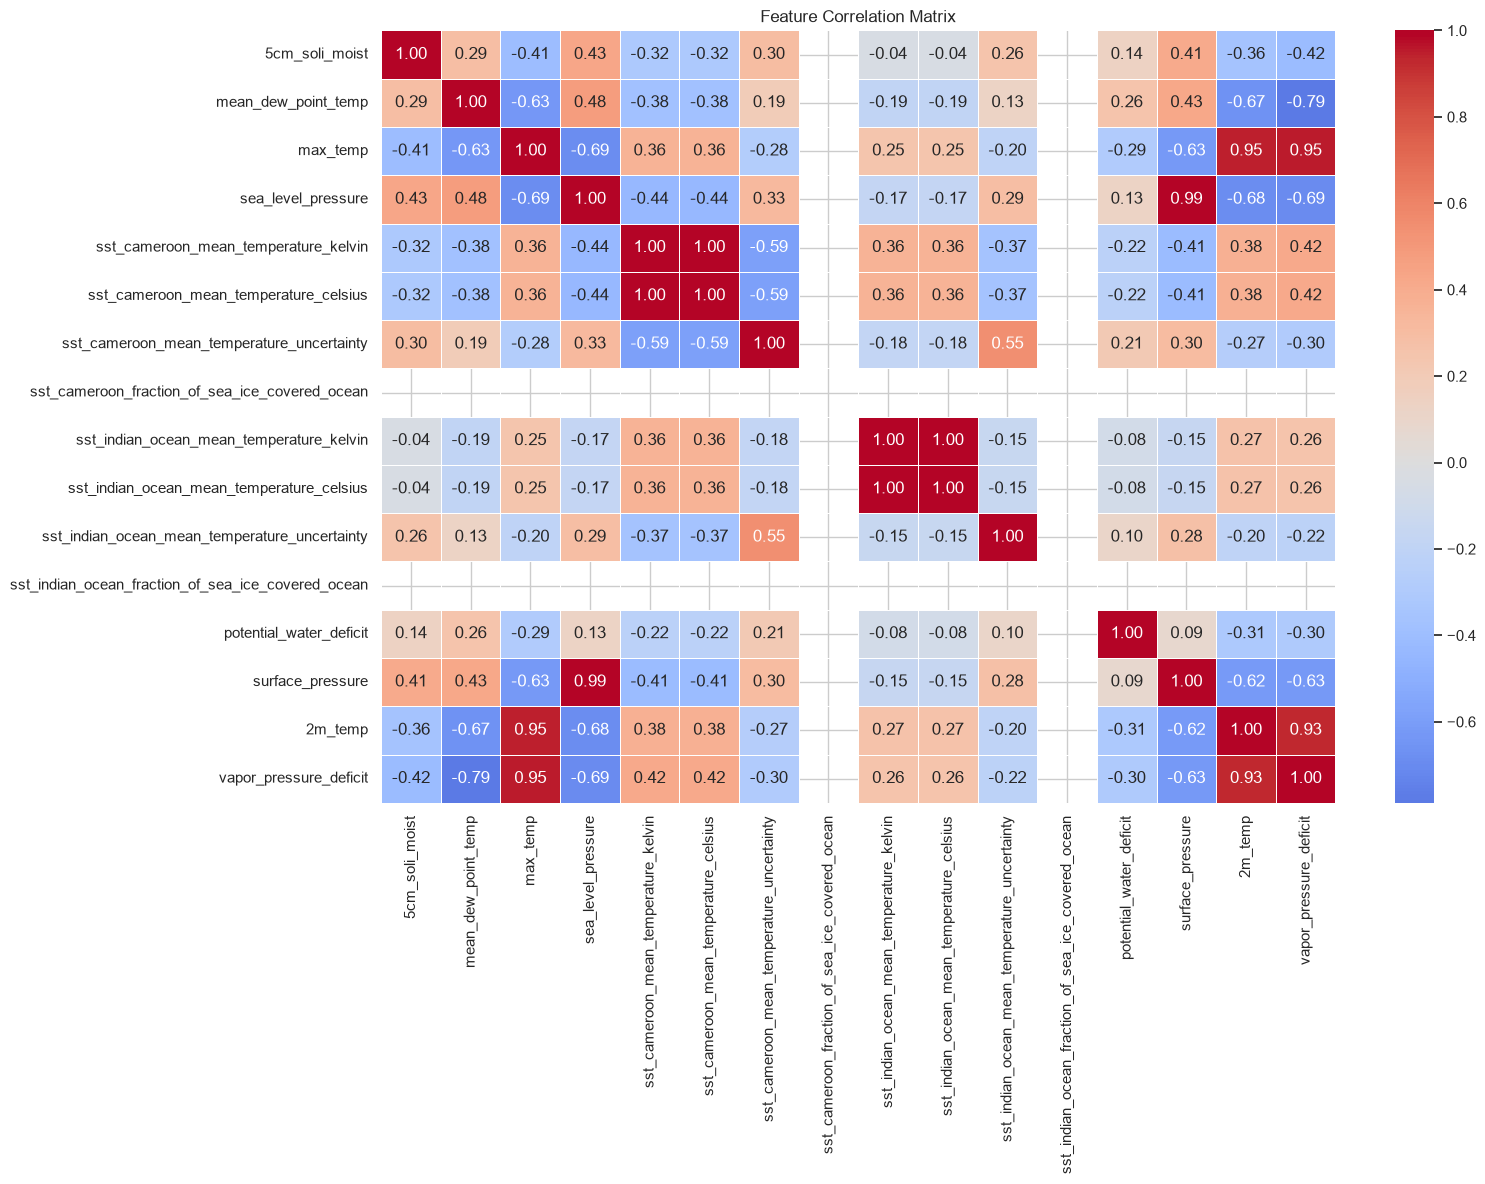

In [11]:
# Calculate Pearson correlation matrix
correlation_matrix = train_merged[numerical_features].corr(method="pearson")

# Visualize correlation matrix
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

#### Key Findings

- The Cameroon SST temperature measurements in Kelvin and Celsius exhibit a perfect rounded Pearson correlation of 1.00.
- The Indian Ocean SST temperature measurements in Kelvin and Celsius also exhibit a perfect rounded Pearson correlation of 1.00.
- Strong positive correlations were identified between:
  - `max_temp` and `2m_temp` (0.95).
  - `max_temp` and `vapor_pressure_deficit` (0.95).
  - `2m_temp` and `vapor_pressure_deficit` (0.93).
  - `sea_level_pressure` and `surface_pressure` (0.99).
- `mean_dew_point_temp` and `vapor_pressure_deficit` exhibit a strong negative correlation (-0.79).
- The two constant sea-ice fraction features have undefined correlations.
- Several feature pairs show strong linear associations, indicating potential redundancy and multicollinearity.

No features are removed at this stage. Their relevance to the target and their impact on model performance will be investigated further.

### 2.4.2 Feature Relationships with Target

This subsection investigates the linear association between each numerical input feature and the binary target variable, `dryspell_warn_7d`.

Pearson correlation coefficients are calculated to identify features with stronger positive or negative associations with the target.

The results provide an initial indication of potential feature relevance, but correlation alone does not establish predictive importance or causation.

,Target Correlation
5cm_soli_moist,-0.3624
sst_cameroon_mean_temperature_uncertainty,-0.3623
sea_level_pressure,-0.3083
surface_pressure,-0.2878
sst_indian_ocean_mean_temperature_uncertainty,-0.2365
mean_dew_point_temp,-0.1411
potential_water_deficit,-0.1267
sst_indian_ocean_mean_temperature_kelvin,0.1116
sst_indian_ocean_mean_temperature_celsius,0.1116
2m_temp,0.2465


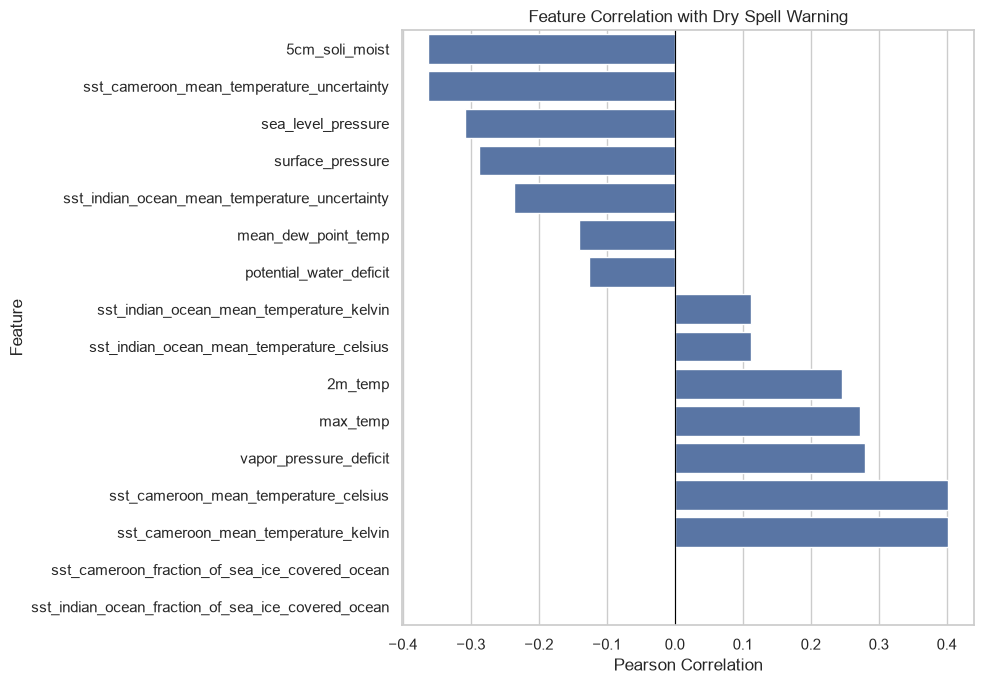

In [12]:
# Calculate correlations between input features and the target
target_correlations = (
    train_merged[numerical_features]
    .corrwith(train_merged["dryspell_warn_7d"])
    .sort_values()
)

# Display correlation values
display(
    target_correlations.to_frame(name="Target Correlation")
    .round(4)
)

# Visualize target correlations
plt.figure(figsize=(10, 7))

sns.barplot(
    x=target_correlations.values,
    y=target_correlations.index
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.title("Feature Correlation with Dry Spell Warning")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

#### Key Findings

- `sst_cameroon_mean_temperature_kelvin` and its Celsius counterpart exhibit the strongest positive correlation with the target (0.4019).
- `vapor_pressure_deficit` (0.2804), `max_temp` (0.2726), and `2m_temp` (0.2465) show positive associations with the target.
- `5cm_soli_moist` exhibits the strongest negative correlation (-0.3624).
- `sst_cameroon_mean_temperature_uncertainty` also shows a negative correlation (-0.3623).
- `sea_level_pressure` (-0.3083) and `surface_pressure` (-0.2878) exhibit negative associations.
- No individual feature demonstrates an exceptionally strong linear correlation with the target.
- Constant sea-ice fraction features have undefined correlations.

These results provide preliminary insights into feature-target relationships but do not establish causality or determine predictive importance.

## 2.5 Temporal Analysis

This section investigates the temporal behavior of dry spell warning events throughout the training period.

The analysis examines changes in warning frequency across years and months to identify potential temporal patterns and variations.

### 2.5.1 Target Distribution Over Time

This subsection examines the annual distribution of dry spell warning events.

The number of observations and the proportion of positive target cases (Class 1) are calculated for each year.

This analysis helps identify interannual variations in dry spell warning frequency.

,year,total_observations,warning_cases,warning_rate
0,2002,123,8,6.50
1,2003,123,27,21.95
2,2004,123,19,15.45
3,2005,123,27,21.95
4,2006,123,18,14.63
5,2007,123,23,18.70
6,2008,123,27,21.95
7,2009,123,31,25.20
8,2010,123,25,20.33
9,2011,123,28,22.76


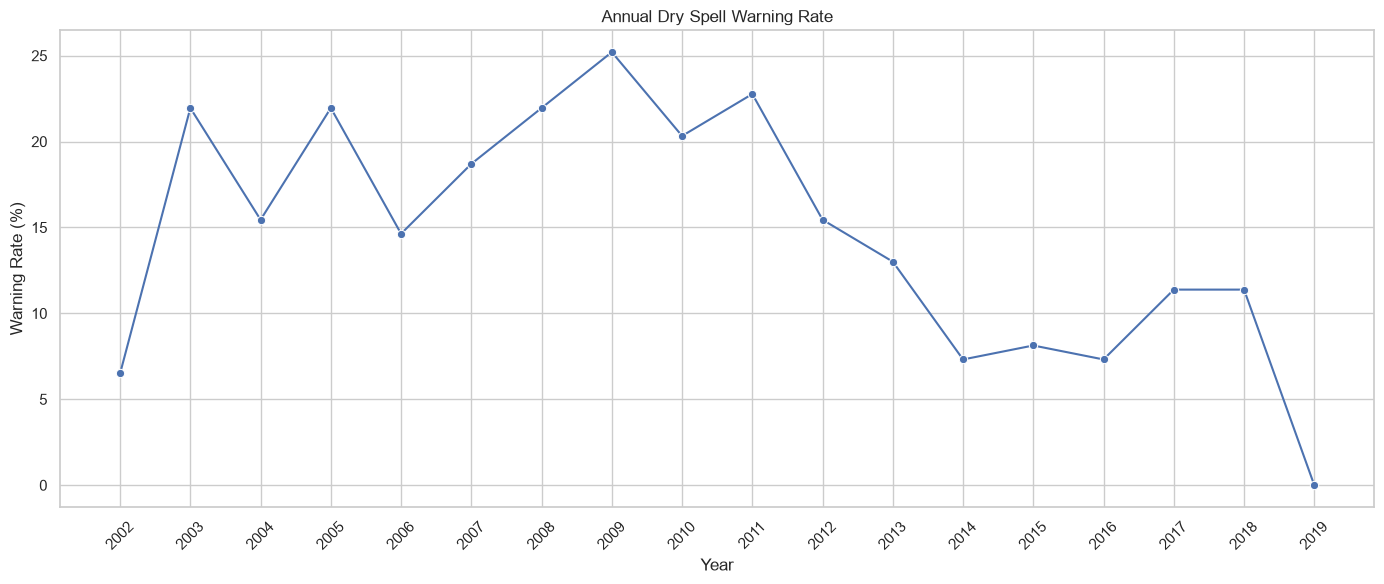

In [13]:
# Extract year from date
train_merged["year"] = train_merged["date"].dt.year

# Calculate annual target statistics
yearly_target = (
    train_merged.groupby("year")["dryspell_warn_7d"]
    .agg(
        total_observations="count",
        warning_cases="sum",
        warning_rate="mean"
    )
    .reset_index()
)

yearly_target["warning_rate"] *= 100

display(yearly_target.round(2))

# Plot annual warning rate
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_target,
    x="year",
    y="warning_rate",
    marker="o"
)

plt.title("Annual Dry Spell Warning Rate")
plt.xlabel("Year")
plt.ylabel("Warning Rate (%)")
plt.xticks(yearly_target["year"], rotation=45)
plt.tight_layout()
plt.show()